<a href="https://colab.research.google.com/github/leninworld/odsc_2026_causal_inference_tutorial/blob/main/odsc_candy_doubleml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Candy-store ad incrementality with DoubleML
**Entirely synthetic teaching example — no customer or campaign records.**

Open this notebook in Google Colab, select a Python CPU runtime, and choose **Run all**.
No Drive mount, credentials, CSV upload or local paths are required. The notebook creates its own CSVs.
Internet is required for the installation cell. Tested package versions are pinned below.
**If Colab asks for a session/runtime restart after installation, restart it, then choose Run all again.**
The installation cell is safe to re-run. Local execution has been checked; actual Google Colab execution
has not been verified. A successful install alone does not verify the rest of the notebook.

We model a fictional retail candy store running a Meta ad campaign (a hypothetical platform example,
not an actual Meta dataset or integration). There are **100 exposed and 500 unexposed users**.
We then randomly retain 100 unexposed users, without inspecting their outcomes.

Plan: causal question → synthetic history → four exposure/conversion quadrants → downsampling →
cross-fitted DoubleML IRM → OLS-based CATE → diagnostics and limitations.
This uses the `DoubleMLIRM.cate(linear_basis)` approach in the supplied L5 heterogeneity lecture.
There is **no causal forest** in this demonstration.

In [ ]:
#%pip install -q doubleml==0.10.1 numpy==2.0.2 pandas==2.2.3 scipy==1.13.1 scikit-learn==1.6.1 statsmodels==0.14.4 matplotlib==3.9.4

In [1]:
%pip install -q DoubleML scikit-learn pandas statsmodels matplotlib

In [3]:
import sys
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from doubleml import DoubleMLData, DoubleMLIRM
from IPython.display import display

SEED = 20260929
print('Python:', sys.version.split()[0])
for package in ['doubleml', 'numpy', 'pandas', 'scikit-learn', 'statsmodels']:
    print(package, metadata.version(package))

Python: 3.13.16
doubleml 0.11.4
numpy 2.1.3
pandas 2.2.3
scikit-learn 1.6.1
statsmodels 0.15.0


## 1. Define what we want to estimate

* Unit: one eligible adult retail user. History: 90 days before the campaign. Outcome: purchase
  conversion during the subsequent 14-day campaign window, observed for **both arms**.
* Treatment `exposed`: at least one exposure to the same hypothetical ad creative during that window.
  Assume a well-defined exposure intervention, comparable delivery versions and no spillovers.
* Primary outcome `conversion`: any candy purchase, not an ad click. Clicks are not used to select users
  or adjust the model. Non-purchasers remain in the data with zero quantity/spend.
* ATE: average change in conversion probability in the declared analysis population.
* CATE: average effect conditional on age and prior spending. An OLS basis approximates this function;
  a prediction for one user's characteristics is **not** their individual treatment effect (ITE).

Identification requires no unmeasured confounding conditional on our pre-campaign features,
overlap, consistency, no interference (one user's ad does not change another user's purchase), and
correct temporal ordering. These assumptions hold by design in the simulator, not automatically in practice.

Age, gender, income and pre-campaign purchase history are permitted controls. User ID, campaign
conversion, campaign item price/quantity/spend and synthetic truth columns are **excluded**.
Demographic categories here are fictional; real use requires appropriate consent and governance.

In [4]:
rng = np.random.default_rng(SEED)
n = 600
users = pd.DataFrame({
    'user_id': [f'candy_{i:04d}' for i in range(n)],
    'age': rng.integers(18, 76, n),
    'gender': rng.choice(['woman', 'man', 'nonbinary'], n, p=[0.48, 0.48, 0.04]),
    'income': np.round(rng.uniform(25000, 150000, n), 2),
})
# Three monthly historical observations per user, including zero-purchase months.
history_rows = []
for user in users.itertuples(index=False):
    for month in [-3, -2, -1]:
        item_price = float(rng.choice([2.0, 3.0, 4.0, 5.0]))
        quantity = int(rng.poisson(2 + user.income / 50000))
        history_rows.append([user.user_id, month, item_price, quantity, item_price * quantity])
history = pd.DataFrame(history_rows, columns=[
    'user_id', 'month_before_campaign', 'item_price', 'quantity', 'total_spend'])
history = history.merge(users, on='user_id', validate='many_to_one')
summary = history.groupby('user_id').agg(
    history_item_price=('item_price', 'mean'),
    history_quantity=('quantity', 'sum'),
    history_total_spend=('total_spend', 'sum')).reset_index()
users = users.merge(summary, on='user_id', validate='one_to_one')
age_scaled = (users.age.to_numpy() - 45) / 20
income_scaled = (users.income.to_numpy() - 75000) / 50000
history_scaled = (users.history_total_spend.to_numpy() - 45) / 30
# Exposure depends on history and demographics: the arms are not randomized.
log_odds = 0.30 * age_scaled + 0.30 * income_scaled + 0.45 * history_scaled
low, high = -12., 12.
for _ in range(80):
    midpoint = (low + high) / 2
    if expit(midpoint + log_odds).sum() > 100:
        high = midpoint
    else:
        low = midpoint
proposal_propensity = expit((low + high) / 2 + log_odds)
# Condition on exactly 100 exposed, without using any campaign outcomes.
# These proposal probabilities are NOT the exact fixed-count inclusion probabilities.
for attempt in range(10000):
    treatment = rng.binomial(1, proposal_propensity)
    if treatment.sum() == 100:
        break
else:
    raise RuntimeError('Could not construct the fixed-count teaching sample.')
users['exposed'] = treatment
p0 = expit(-1.6 + 0.20 * age_scaled + 0.35 * income_scaled
           + 0.45 * history_scaled + 0.10 * (users.gender.to_numpy() == 'woman'))
# Known heterogeneous probability effect, deliberately linear in the CATE basis.
tau = 0.06 + 0.015 * age_scaled + 0.008 * history_scaled
p1 = p0 + tau
assert np.all((p0 > 0) & (p1 < 1) & (tau > 0))
uniform_outcome = rng.uniform(size=n)
users['conversion'] = (uniform_outcome < np.where(treatment == 1, p1, p0)).astype(int)
users['campaign_item_price'] = rng.choice([2.0, 3.0, 4.0, 5.0], n)
users['campaign_quantity'] = users.conversion * (1 + rng.poisson(2, n))
users['campaign_total_spend'] = users.campaign_item_price * users.campaign_quantity
truth = pd.DataFrame({'user_id': users.user_id, 'p0': p0, 'p1': p1, 'true_cate': tau})
assert users.exposed.value_counts().to_dict() == {0: 500, 1: 100}
assert len(history) == 1800 and users.user_id.is_unique
assert np.allclose(history.total_spend, history.item_price * history.quantity)
users.to_csv('candy_users_600.csv', index=False)
history.to_csv('candy_purchase_history.csv', index=False)
truth.to_csv('candy_simulation_truth.csv', index=False)
display(users.head())
display(history.head())

,user_id,age,gender,income,history_item_price,history_quantity,history_total_spend,exposed,conversion,campaign_item_price,campaign_quantity,campaign_total_spend
0,candy_0000,30,nonbinary,42588.92,2.666667,7,18.0,0,0,4.0,0,0.0
1,candy_0001,38,woman,132437.48,2.666667,12,28.0,0,0,5.0,0,0.0
2,candy_0002,48,woman,26730.70,3.000000,9,24.0,0,1,4.0,1,4.0
3,candy_0003,63,man,87400.92,4.333333,9,41.0,0,1,3.0,5,15.0
4,candy_0004,68,man,103142.07,2.333333,12,30.0,0,0,4.0,0,0.0


,user_id,month_before_campaign,item_price,quantity,total_spend,age,gender,income
0,candy_0000,-3,2.0,3,6.0,30,nonbinary,42588.92
1,candy_0000,-2,3.0,1,3.0,30,nonbinary,42588.92
2,candy_0000,-1,3.0,3,9.0,30,nonbinary,42588.92
3,candy_0001,-3,3.0,2,6.0,38,woman,132437.48
4,candy_0001,-2,3.0,2,6.0,38,woman,132437.48


## 2. Four quadrants: exposure × conversion

The cells are **exposed/purchased, exposed/not purchased, unexposed/purchased,
unexposed/not purchased**. This is not a clicker/non-clicker table. The difference between raw
conversion rates mixes selection and treatment effects; it is not automatically causal.

,No conversion,Conversion
Not exposed,416,84
Exposed,71,29


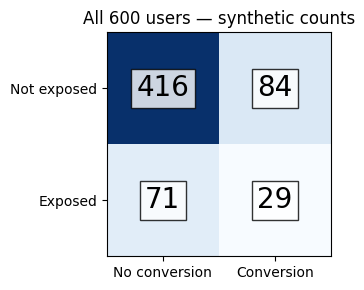

,count,mean
exposed,,
0,500,0.168
1,100,0.290


In [5]:
def quadrants(frame, title):
    counts = pd.crosstab(frame.exposed, frame.conversion).reindex(
        index=[0, 1], columns=[0, 1], fill_value=0)
    counts.index = ['Not exposed', 'Exposed']
    counts.columns = ['No conversion', 'Conversion']
    display(counts)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.imshow(counts, cmap='Blues')
    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(counts.iloc[row, col]), ha='center', va='center',
                    fontsize=20, color='black', bbox=dict(facecolor='white', alpha=.8))
    ax.set_xticks([0, 1], counts.columns)
    ax.set_yticks([0, 1], counts.index)
    ax.set_title(title + ' — synthetic counts')
    plt.tight_layout()
    plt.show()
quadrants(users, 'All 600 users')
display(users.groupby('exposed').conversion.agg(['count', 'mean']))

## 3. Downsample controls: 100 versus 100

Keep all exposed users and draw 100 of the 500 unexposed users uniformly **without replacement**.
Do not choose controls based on conversion or tune the random seed to get a favorable effect.

Equal sample sizes do not balance age/history, remove confounding, or fix overlap. This operation
discards information and changes the covariate mix. We therefore report a **downsampled-sample target**
separately from the full-cohort target. We do not claim the unweighted 200-user ATE represents all 600.
Recovering a population estimand after unequal sampling needs an explicit sampling-weight design;
simply adding a weight to a final regression is not sufficient. The full-data fit is our reference.
The toy fixed-count sample also means the displayed usual asymptotic intervals are teaching
approximations, not an exact randomization analysis.

,No conversion,Conversion
Not exposed,88,12
Exposed,71,29


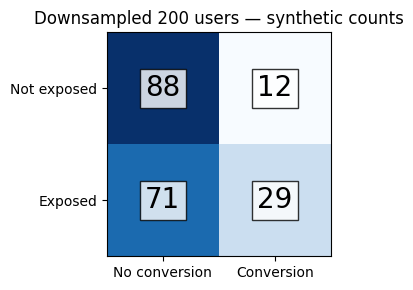

,age,income,history_total_spend
exposed,,,
0,44.18,89091.5209,38.74
1,50.73,100484.4456,44.83


In [6]:
downsampled = pd.concat([
    users.loc[users.exposed == 1],
    users.loc[users.exposed == 0].sample(n=100, replace=False, random_state=SEED),
]).sample(frac=1, random_state=SEED).reset_index(drop=True)
downsampled.to_csv('candy_users_balanced_200.csv', index=False)
assert downsampled.exposed.value_counts().to_dict() == {0: 100, 1: 100}
quadrants(downsampled, 'Downsampled 200 users')
display(downsampled.groupby('exposed')[['age', 'income', 'history_total_spend']].mean())

## 4. DoubleML IRM: learn counterfactual outcome probabilities

We use the **Interactive Regression Model (IRM), ATE score**, because exposure is binary and effects
can vary. This is not the constant-effect PLR residual slope.

Three-fold stratified cross-fitting learns `g0(X)` (conversion without exposure), `g1(X)`
(conversion with exposure), and `m(X)` (exposure probability) outside each held-out fold.
Logistic regression with training-fold scaling provides transparent probability nuisance models.
No class balancing is applied to the probability models. OLS comes later, for CATE.

The orthogonal pseudo-outcome is:

`g1 - g0 + T*(Y-g1)/m - (1-T)*(Y-g0)/(1-m)`.

Its average estimates the ATE under the design assumptions. Neyman orthogonality gives local,
first-order robustness to small nuisance errors; it neither randomizes exposure nor eliminates
unmeasured confounding. Version 0.10.1 applies explicit 0.01 propensity truncation here;
we report how many fitted probabilities hit that boundary.

**Warning you may see during `fit()`:** `The estimated nu2 for exposed is not positive.`
In the pinned DoubleML 0.10.1 implementation, this triggers a non-orthogonal fallback for
the sensitivity component `nu2` and its score. The warning itself does not replace the ATE
or its standard error. It is a diagnostic concern, not a warning to suppress or a guarantee
that sensitivity results are trustworthy. We do **not** execute omitted-confounding
`sensitivity_analysis()` or `sensitivity_benchmark()` here. Those require separate validation.
Source: [DoubleML 0.10.1 sensitivity validation](https://github.com/DoubleML/doubleml-for-py/blob/0.10.1/doubleml/double_ml.py).


In [7]:
FEATURES = ['age', 'income', 'history_item_price', 'history_quantity', 'history_total_spend']
def fit_irm(frame, seed=SEED):
    frame = frame.reset_index(drop=True)
    X = pd.concat([frame[FEATURES], pd.get_dummies(
        frame.gender, prefix='gender', dtype=float)], axis=1)
    model_frame = pd.concat([frame[['conversion', 'exposed']], X], axis=1)
    data = DoubleMLData(model_frame, y_col='conversion', d_cols='exposed', x_cols=list(X.columns))
    learner = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
    np.random.seed(seed)
    model = DoubleMLIRM(data, ml_g=learner, ml_m=learner,
                        n_folds=3, n_rep=1, score='ATE',
                        trimming_rule='truncate', trimming_threshold=0.01)
    model.fit(n_jobs_cv=1)
    # Each observation must appear in one held-out fold, with no train/test overlap.
    held_out = []
    for train, test in model.smpls[0]:
        assert not set(train).intersection(test)
        held_out.extend(test)
        assert set(frame.iloc[train].exposed) == {0, 1}
    assert sorted(held_out) == list(range(len(frame)))
    return model

full_model = fit_irm(users)
downsampled_model = fit_irm(downsampled)
display(full_model.summary)
display(downsampled_model.summary)

/usr/local/lib/python3.13/dist-packages/doubleml/double_ml.py:1636: UserWarning: The estimated nu2 for exposed is not positive. Re-estimation based on riesz representer (non-orthogonal).
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/doubleml/double_ml.py:1636: UserWarning: The estimated nu2 for exposed is not positive. Re-estimation based on riesz representer (non-orthogonal).
  warnings.warn(msg, UserWarning)


,coef,std err,t,P>|t|,2.5 %,97.5 %
exposed,0.012028,0.043952,0.273657,0.784348,-0.074116,0.098171


,coef,std err,t,P>|t|,2.5 %,97.5 %
exposed,-0.034184,0.409801,-0.083417,0.93352,-0.837379,0.769011


## 5. Absolute lift and relative lift have different units

An effect of 0.02 is **2 percentage points**, not 2% relative lift. Relative lift is
`100 * ATE / estimated no-ad conversion probability` for the **same population**.
We estimate that denominator with a cross-fitted augmented counterfactual mean.
The ratio below is a point estimate only: an ATE confidence interval is not a valid ratio interval.
Do not report a ratio when its denominator is non-positive or implausibly small.

In [8]:
def result_row(frame, model, label):
    g0 = model.predictions['ml_g0'].reshape(-1)
    m = model.predictions['ml_m'].reshape(-1)
    y, t = frame.conversion.to_numpy(), frame.exposed.to_numpy()
    mu0 = np.mean(g0 + (1-t) * (y-g0) / (1-m))
    interval = model.confint().iloc[0].to_numpy()
    cohort_truth = frame[['user_id']].merge(truth, on='user_id', validate='one_to_one')
    return {'population': label, 'n': len(frame),
            'raw_difference_pp': 100*(frame.loc[t == 1, 'conversion'].mean()
                                      - frame.loc[t == 0, 'conversion'].mean()),
            'DML_ATE_pp': 100*model.coef[0], 'CI_low_pp': 100*interval[0],
            'CI_high_pp': 100*interval[1], 'estimated_no_ad_rate': mu0,
            'relative_lift_percent_point_estimate': 100*model.coef[0]/mu0 if mu0 > .01 else np.nan,
            'synthetic_true_ATE_pp': 100*cohort_truth.true_cate.mean()}
results = pd.DataFrame([result_row(users, full_model, 'Full 600-user cohort'),
                        result_row(downsampled, downsampled_model, 'Downsampled 200-user sample')])
display(results.round(3))
print('Interpret results only after the weight and influence diagnostics below; extreme fitted propensities can dominate uncertainty.')

,population,n,raw_difference_pp,DML_ATE_pp,CI_low_pp,CI_high_pp,estimated_no_ad_rate,relative_lift_percent_point_estimate,synthetic_true_ATE_pp
0,Full 600-user cohort,600,12.2,1.203,-7.412,9.817,0.177,6.812,5.970
1,Downsampled 200-user sample,200,17.0,-3.418,-83.738,76.901,0.256,-13.352,6.098


Interpret results only after the weight and influence diagnostics below; extreme fitted propensities can dominate uncertainty.


## 6. OLS-based CATE, following the lecture

DoubleML's `cate()` fits a **best linear projection of the orthogonal pseudo-outcome**, using
an intercept, age and pre-campaign spending. It is not naive `conversion ~ exposure` regression.
We use HC3 heteroskedasticity-robust uncertainty. A linear basis is a modeling restriction;
outside this synthetic design the true CATE may not be linear. Predictions can leave plausible
probability-effect bounds in small samples: do not clip them to hide instability.

Age is centered at 45 and scaled by 20 years; history spend at $45 and scaled by $30.
The intercept is the predicted effect at those reference values. Slopes describe differences in
**ad effects**, not the causal effect of changing someone's age or past spending.

In [11]:
def basis(frame):
    return pd.DataFrame({
        'intercept': np.ones(len(frame)),
        'age_20years': (frame.age.to_numpy() - 45) / 20,
        'history_spend_30dollars': (frame.history_total_spend.to_numpy() - 45) / 30
    })

# Calculate CATE (returns a list if n_rep > 1)
cate = downsampled_model.cate(basis(downsampled), cov_type='HC3')
print(cate)

profiles = pd.DataFrame({'age': [25, 45, 65], 'history_total_spend': [45., 45., 45.]})

# Select the first repetition [0] to access the underlying DoubleMLBLP model
predictions = cate[0].blp_model.get_prediction(basis(profiles)).summary_frame(alpha=.05)

display(pd.concat([
    profiles,
    predictions[['mean', 'mean_ci_lower', 'mean_ci_upper']].mul(100)
        .rename(columns={
            'mean': 'CATE_pp',
            'mean_ci_lower': 'pointwise_low_pp',
            'mean_ci_upper': 'pointwise_high_pp'
        })
], axis=1))

print('These are pointwise intervals at fixed example profiles, not simultaneous bands or ITEs.')

================== DoubleMLBLP Object ==================

------------------ Fit summary ------------------
                             coef   std err         t     P>|t|    [0.025  \
intercept                0.045975  0.483528  0.095083  0.924249 -0.901723   
age_20years             -0.072272  0.233232 -0.309873  0.756657 -0.529399   
history_spend_30dollars  0.665209  0.823259  0.808019  0.419079 -0.948349   

                           0.975]  
intercept                0.993674  
age_20years              0.384854  
history_spend_30dollars  2.278767  


,age,history_total_spend,CATE_pp,pointwise_low_pp,pointwise_high_pp
0,25,45.0,11.824784,-112.061632,135.711199
1,45,45.0,4.597550,-90.172289,99.367388
2,65,45.0,-2.629685,-85.055974,79.796605


These are pointwise intervals at fixed example profiles, not simultaneous bands or ITEs.


## 7. Diagnostics before interpretation

Inspect held-out propensity distributions, probability error, covariate differences, inverse weights,
and influence concentration. An overlapping histogram does not prove conditional overlap, and a
low Brier score does not prove unconfoundedness. We do not tune the seed for significance.

The executed downsampled run has one exposed user at fitted propensity 0.01 and one unexposed
user at 0.99. Their respective weights, `1/m` and `1/(1-m)`, are about 100. The arm-specific
Kish effective sample sizes are about **8.39 and 8.65**, despite 100 users per arm. This weight
concentration and the observed score variability explain why the reported interval is extremely wide;
attributing it only to sample size misses the important mechanism.

These are **estimated-propensity/support warnings**, not proof that the data-generating process
violates positivity. Nuisance estimation error can also produce extreme fitted probabilities.
Truncation caps extreme weights at 100 here; it does not create the extremes. A truncation choice
changes the score and requires sensitivity checks. Boundary counts below refer to the stored,
already truncated probabilities, not measured frequencies of raw predictions changed by clipping.

Kish ESS is `(sum(w)**2)/sum(w**2)` within each observed arm. It describes weight concentration,
not a replacement sample size for calculating the AIPW standard error. For this single-repetition,
unnormalized IRM ATE score, the score derivative is -1, so its centered score is the estimated influence
function. We reconstruct it below and check that `sqrt(mean(psi**2)/n)` matches DoubleML's standard error.


Full Brier: 0.134 at truncation boundary: 7
Downsampled Brier: 0.245 at truncation boundary: 2


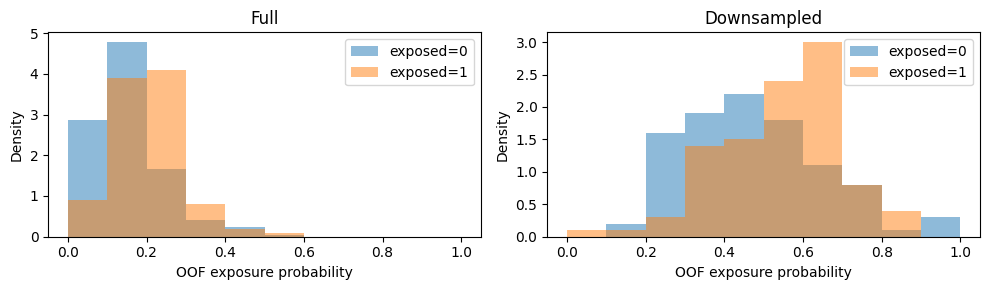

,full_SMD,downsampled_SMD
age,0.305385,0.416492
income,0.436298,0.327185
history_item_price,0.167513,0.128496
history_quantity,0.360459,0.373552
history_total_spend,0.410850,0.375182


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=True)
for ax, frame, model, label in zip(axes, [users, downsampled], [full_model, downsampled_model], ['Full', 'Downsampled']):
    m = model.predictions['ml_m'].reshape(-1)
    assert np.isfinite(m).all()
    for arm in [0, 1]:
        ax.hist(m[frame.exposed.to_numpy() == arm], bins=np.linspace(0, 1, 11),
                alpha=.5, density=True, label=f'exposed={arm}')
    ax.set(title=label, xlabel='OOF exposure probability', ylabel='Density')
    ax.legend()
    print(label, 'Brier:', round(brier_score_loss(frame.exposed, m), 3),
          'at truncation boundary:', int(((m <= .0100001) | (m >= .9899999)).sum()))
plt.tight_layout()
plt.show()
def standardized_differences(frame):
    rows = []
    for feature in FEATURES:
        a = frame.loc[frame.exposed == 1, feature]
        b = frame.loc[frame.exposed == 0, feature]
        rows.append((feature, (a.mean()-b.mean()) / np.sqrt((a.var()+b.var())/2)))
    return pd.Series(dict(rows))
display(pd.DataFrame({'full_SMD': standardized_differences(users),
                      'downsampled_SMD': standardized_differences(downsampled)}))

In [13]:
def weight_influence_diagnostics(frame, model, label):
    t = frame.exposed.to_numpy()
    y = frame.conversion.to_numpy()
    m = model.predictions['ml_m'].reshape(-1)
    g0 = model.predictions['ml_g0'].reshape(-1)
    g1 = model.predictions['ml_g1'].reshape(-1)
    pseudo_outcome = g1-g0 + t*(y-g1)/m - (1-t)*(y-g0)/(1-m)
    psi = pseudo_outcome - model.coef[0]
    assert np.allclose(psi, model.psi.reshape(-1))
    reproduced_se = np.sqrt(np.mean(psi**2)/len(frame))
    assert np.isclose(reproduced_se, model.se[0])
    rows = []
    for arm in [1, 0]:
        p = m[t == arm]
        weights = 1/p if arm == 1 else 1/(1-p)
        rows.append({'sample': label, 'arm': 'Exposed' if arm else 'Unexposed',
                     'n': len(p), 'Kish_ESS': weights.sum()**2/np.sum(weights**2),
                     'max_inverse_weight': weights.max(),
                     'at_lower_boundary': np.isclose(p, .01).sum(),
                     'at_upper_boundary': np.isclose(p, .99).sum()})
    influence = {'sample': label, 'score_sd': psi.std(ddof=0),
                 'max_abs_score': np.abs(psi).max(),
                 'top_2_share_squared_score': np.sort(psi**2)[-2:].sum()/np.sum(psi**2),
                 'reproduced_ATE_SE_pp': 100*reproduced_se}
    return rows, influence

weight_rows, influence_rows = [], []
for frame, model, label in [(users, full_model, 'Full'),
                            (downsampled, downsampled_model, 'Downsampled')]:
    rows, influence = weight_influence_diagnostics(frame, model, label)
    weight_rows.extend(rows)
    influence_rows.append(influence)
display(pd.DataFrame(weight_rows).round(3))
display(pd.DataFrame(influence_rows).round(3))
print('Diagnostic verdict: the downsampled ATE/CATE is too unstable for a useful quantitative lift claim.')
print('Investigate nuisance estimation and support before interpreting the effect; do not select a favorable seed.')


,sample,arm,n,Kish_ESS,max_inverse_weight,at_lower_boundary,at_upper_boundary
0,Full,Exposed,100,32.346,100.000,1,0
1,Full,Unexposed,500,491.865,2.078,6,0
2,Downsampled,Exposed,100,8.390,100.000,1,0
3,Downsampled,Unexposed,100,8.646,100.000,0,1


,sample,score_sd,max_abs_score,top_2_share_squared_score,reproduced_ATE_SE_pp
0,Full,1.077,8.735,0.186,4.395
1,Downsampled,5.795,68.395,0.976,40.980


Diagnostic verdict: the downsampled ATE/CATE is too unstable for a useful quantitative lift claim.
Investigate nuisance estimation and support before interpreting the effect; do not select a favorable seed.


## 8. Take-home checklist and files

* Confirm treatment, population, 90-day history and 14-day outcome windows before estimation.
* Keep non-purchasers and both exposure arms. Never adjust for campaign outcomes or clicks.
* Check overlap and cross-fitting; equal counts are not covariate balance.
* State whether the estimate describes the full cohort or the downsampled population.
* Report ATE in percentage points, relative lift separately, and uncertainty honestly.
* CATE is a conditional average, not an observed individual counterfactual.
* Repeat with alternative folds/control samples as a stability exercise; do not select favorable results.
* Real data need unmeasured-confounding sensitivity and preferably randomized holdout validation.
* This notebook is educational, not evidence of campaign performance or an unbiasedness guarantee.

Generated files: `candy_users_600.csv`, `candy_users_balanced_200.csv`,
`candy_purchase_history.csv` (1,800 monthly rows), and `candy_simulation_truth.csv` (teaching-only truth).
In Colab, use the Files sidebar to download them.

References: [DoubleML IRM](https://docs.doubleml.org/stable/api/generated/doubleml.irm.DoubleMLIRM.html)
and [CATE guide](https://docs.doubleml.org/stable/guide/heterogeneity.html).
Lecture precedent: supplied `L5_heterogeneity/heterogeneity.html`, Basic CATEs: linear basis and `cate()`.
The code is original synthetic tutorial code, not a copy of private implementation.

The word `balanced` in the retained CSV filename is legacy naming only: it means equal arm counts,
not covariate balance. All displayed sample labels use **downsampled**. The age SMD rises from
about 0.305 to 0.416 after downsampling in this seed, illustrating that random retention can worsen
observed balance. No clipping-threshold comparison, repeated-split study, production monitoring,
or omitted-confounding sensitivity analysis has been executed in this notebook.
